# Notebook 04 — Customer Segmentation using K-Means

**Goal:** Segment customers using the behavioural feature matrix created in Notebook 03.

This notebook:
1. Retrieves the feature files from Google Drive.
2. Scales behavioural features.
3. Tests a range of cluster counts using inertia (elbow) and silhouette score.
4. Fits a K-Means model.
5. Attaches cluster labels to customer IDs.
6. Profiles the clusters and exports the outputs.

**Important modelling decisions**
- Do not use `customer_id` as a feature.
- Do not use the synthetic ground-truth archetype.
- Billing status / days overdue are not clustering inputs. They can be joined later for operational analysis.
- K-Means labels are arbitrary numbers. We interpret clusters only after examining their feature profiles.


## 1. Mount Google Drive and locate Notebook 03 outputs

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib

MYDRIVE = Path('/content/drive/MyDrive')

# Search for the output created by Notebook 03.
matches = list(MYDRIVE.rglob('customer_features_unscaled.csv'))
if not matches:
    raise FileNotFoundError(
        "Could not find customer_features_unscaled.csv in MyDrive. "
        "Run Notebook 03 and check that it exported the expected file."
    )

FEATURE_FILE = matches[0]
OUTPUT_DIR = FEATURE_FILE.parent / 'segmentation_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Feature file:", FEATURE_FILE)
print("Output folder:", OUTPUT_DIR)


Mounted at /content/drive
Feature file: /content/drive/MyDrive/customer_loyalty_synthetic_20k/customer_loyalty_synthetic_20k/processed/customer_features_unscaled.csv
Output folder: /content/drive/MyDrive/customer_loyalty_synthetic_20k/customer_loyalty_synthetic_20k/processed/segmentation_outputs


## 2. Load feature matrix and customer ID mapping

In [2]:
X_raw = pd.read_csv(FEATURE_FILE)

# Locate the ID mapping produced by Notebook 03.
mapping_matches = list(FEATURE_FILE.parent.rglob('customer_id_mapping.csv'))
if not mapping_matches:
    raise FileNotFoundError(
        "customer_id_mapping.csv was not found beside the feature file. "
        "Check Notebook 03 outputs."
    )

id_map = pd.read_csv(mapping_matches[0])

print("Feature matrix shape:", X_raw.shape)
print("ID mapping shape:", id_map.shape)
display(X_raw.head())
display(id_map.head())


Feature matrix shape: (20000, 18)
ID mapping shape: (20000, 1)


,tenure_months,avg_active_days,avg_login_count,avg_app_sessions,avg_service_usage,avg_engagement_score,latest_engagement_score,successful_transaction_count,total_transaction_value_inr,avg_transaction_value_inr,median_transaction_value_inr,transaction_recency_days,campaigns_received,campaign_acceptance_rate,active_day_rate,sessions_per_login,transactions_per_observed_month,spend_per_transaction_inr
0,4,2.250000,1.658228,1.228665,0.847298,43.491667,45.8,2.302585,7.769936,5.576084,5.201256,54.0,1.609438,0.0,0.075000,0.568627,0.750000,263.035556
1,38,11.166667,2.751535,2.120264,2.025953,48.483333,48.8,2.397895,9.140123,6.838503,6.680478,37.0,1.791759,0.4,0.372222,0.500000,0.833333,932.091000
2,6,15.750000,3.079614,2.719100,2.621039,40.666667,47.1,2.397895,8.096982,5.797133,5.442612,32.0,0.693147,0.0,0.525000,0.682731,0.833333,328.354000
3,4,8.916667,2.668385,2.285778,2.036882,41.800000,49.2,2.302585,7.469780,5.277105,5.099683,62.0,0.693147,0.0,0.297222,0.658385,0.750000,194.802222
4,27,27.750000,3.759260,3.317212,3.124565,80.083333,72.1,2.639057,7.566694,5.007934,4.816808,16.0,1.609438,0.5,0.925000,0.634195,1.083333,148.595385


,customer_id
0,CUST000001
1,CUST000002
2,CUST000003
3,CUST000004
4,CUST000005


## 3. Validate and prepare clustering inputs

We remove identifier-like columns if they accidentally appear in the feature file. The remaining columns must be numeric. Missing and infinite values are handled before scaling; review the printed diagnostics rather than blindly ignoring them.

In [3]:
# Keep customer ID outside the model input.
id_like = [c for c in X_raw.columns if c.lower() in {'customer_id', 'id'}]
X = X_raw.drop(columns=id_like, errors='ignore').copy()

# Convert numeric-looking columns; fail clearly if non-numeric columns remain.
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')

print("Feature columns:", X.columns.tolist())
print("Missing values:", int(X.isna().sum().sum()))
print("Infinite values:", int(np.isinf(X.to_numpy(dtype=float)).sum()))

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))

# Remove constant columns: they cannot help distinguish clusters.
constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
if constant_cols:
    print("Removing constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)

if X.shape[1] < 2:
    raise ValueError("Need at least two usable behavioural features for clustering.")

print("Final modelling matrix:", X.shape)
display(X.describe().T)


Feature columns: ['tenure_months', 'avg_active_days', 'avg_login_count', 'avg_app_sessions', 'avg_service_usage', 'avg_engagement_score', 'latest_engagement_score', 'successful_transaction_count', 'total_transaction_value_inr', 'avg_transaction_value_inr', 'median_transaction_value_inr', 'transaction_recency_days', 'campaigns_received', 'campaign_acceptance_rate', 'active_day_rate', 'sessions_per_login', 'transactions_per_observed_month', 'spend_per_transaction_inr']
Missing values: 0
Infinite values: 0
Final modelling matrix: (20000, 18)


,count,mean,std,min,25%,50%,75%,max
tenure_months,20000.0,51.113800,35.856414,1.0,18.000000,49.000000,80.000000,120.000000
avg_active_days,20000.0,12.666479,8.408905,0.0,6.166667,11.083333,19.750000,30.000000
avg_login_count,20000.0,2.657473,0.866167,0.0,2.277267,2.803360,3.352824,4.116323
avg_app_sessions,20000.0,2.271755,0.811206,0.0,1.884541,2.397895,2.931194,3.661423
avg_service_usage,20000.0,2.117784,0.783137,0.0,1.734601,2.233592,2.756840,3.528809
avg_engagement_score,20000.0,55.042943,27.589196,0.0,37.981250,54.608333,81.472917,99.825000
latest_engagement_score,20000.0,54.374425,29.130575,0.0,34.800000,54.800000,80.100000,100.000000
successful_transaction_count,20000.0,2.304482,0.641257,0.0,1.945910,2.397895,2.772589,3.583519
total_transaction_value_inr,20000.0,7.794897,1.150863,0.0,7.339476,7.976042,8.481592,10.716581
avg_transaction_value_inr,20000.0,5.628141,0.738982,0.0,5.291765,5.601154,6.003966,9.322664


## 4. Scale the features

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled matrix shape:", X_scaled.shape)


Scaled matrix shape: (20000, 18)


## 5. Find a suitable number of clusters

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test a modest range. Silhouette score is computed on a sample for speed.
k_values = range(2, 9)
inertias = []
silhouette_scores = []

sample_size = min(5000, len(X_scaled))
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_scaled), size=sample_size, replace=False)
X_sample = X_scaled[sample_idx]

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_sample, labels[sample_idx])
    )

metrics_df = pd.DataFrame({
    'k': list(k_values),
    'inertia': inertias,
    'silhouette_score': silhouette_scores
})
display(metrics_df)


,k,inertia,silhouette_score
0,2,251748.745963,0.267665
1,3,199248.047978,0.275302
2,4,174433.650000,0.286370
3,5,160456.918536,0.245930
4,6,151537.010294,0.213719
5,7,144313.444098,0.212543
6,8,138974.710682,0.178154


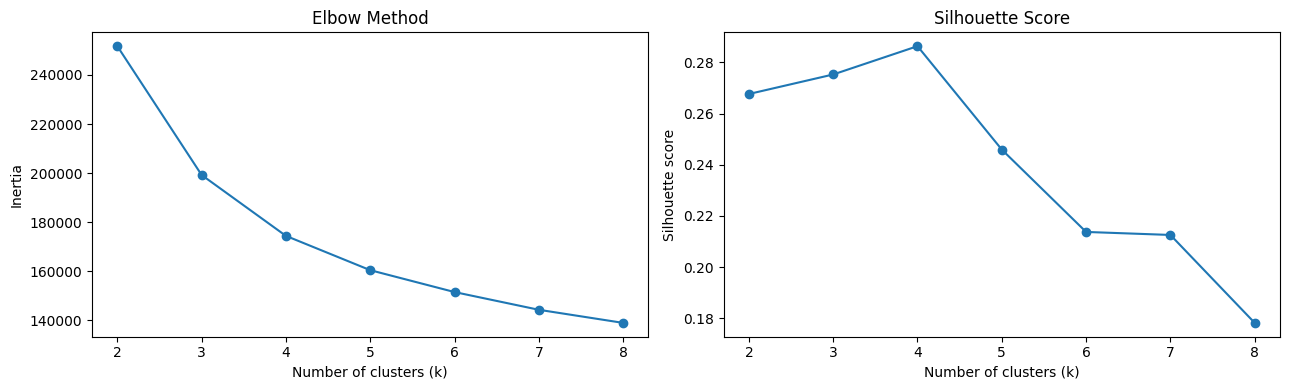

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(metrics_df['k'], metrics_df['inertia'], marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(metrics_df['k'], metrics_df['silhouette_score'], marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette score')

plt.tight_layout()
plt.show()


### Select K

Use both plots and the resulting cluster sizes. A higher silhouette score is generally better, but do not select K using one metric alone. Look for a reasonable elbow, separation, and clusters that are large enough to interpret.

Set `CHOSEN_K` after reviewing the plots. The default below selects the K with the highest tested silhouette score as a starting point—not an automatic final decision.

In [7]:
CHOSEN_K = int(metrics_df.loc[metrics_df['silhouette_score'].idxmax(), 'k'])
print("Suggested K from silhouette score:", CHOSEN_K)

# Change this value after inspecting the elbow and silhouette plots if needed.
# Example: CHOSEN_K = 4


Suggested K from silhouette score: 4


## 6. Fit the final K-Means model

In [8]:
final_model = KMeans(
    n_clusters=CHOSEN_K,
    random_state=42,
    n_init=20
)
cluster_labels = final_model.fit_predict(X_scaled)

segmentation = pd.DataFrame({
    'customer_id': id_map['customer_id'].values,
    'cluster': cluster_labels
})

print("Cluster counts:")
display(segmentation['cluster'].value_counts().sort_index().to_frame('customers'))
print("Cluster proportions:")
display(
    segmentation['cluster'].value_counts(normalize=True)
    .sort_index().mul(100).round(2).to_frame('percentage')
)


Cluster counts:


,customers
cluster,
0,10278
1,161
2,6146
3,3415


Cluster proportions:


,percentage
cluster,
0,51.39
1,0.80
2,30.73
3,17.08


## 7. Build cluster profiles

In [9]:
profile_input = X.copy()
profile_input['cluster'] = cluster_labels

cluster_profile_mean = profile_input.groupby('cluster').mean(numeric_only=True)
cluster_profile_median = profile_input.groupby('cluster').median(numeric_only=True)

display(cluster_profile_mean)
display(cluster_profile_median)


,tenure_months,avg_active_days,avg_login_count,avg_app_sessions,avg_service_usage,avg_engagement_score,latest_engagement_score,successful_transaction_count,total_transaction_value_inr,avg_transaction_value_inr,median_transaction_value_inr,transaction_recency_days,campaigns_received,campaign_acceptance_rate,active_day_rate,sessions_per_login,transactions_per_observed_month,spend_per_transaction_inr
cluster,,,,,,,,,,,,,,,,,,
0,46.126386,10.173323,2.662610,2.260981,2.099087,50.559511,49.903250,2.286520,7.857750,5.691771,5.459530,54.853765,1.337875,0.232127,0.339111,0.647815,0.790677,346.224566
1,43.254658,1.992754,1.176457,0.904209,0.798939,11.471843,9.132298,0.000000,0.000000,0.000000,0.000000,0.000000,1.310546,0.048842,0.066425,0.686513,0.000000,0.000000
2,62.755451,23.161880,3.520698,3.096085,2.921109,86.782113,86.796241,2.898272,8.482053,5.646021,5.387038,36.537585,1.329924,0.526035,0.772063,0.645411,1.471580,309.299704
3,45.543192,1.784602,1.158280,0.885102,0.790484,13.469507,11.614319,1.398537,6.736541,5.669795,5.547453,115.692240,1.340257,0.058975,0.059487,0.680405,0.288043,387.396414


,tenure_months,avg_active_days,avg_login_count,avg_app_sessions,avg_service_usage,avg_engagement_score,latest_engagement_score,successful_transaction_count,total_transaction_value_inr,avg_transaction_value_inr,median_transaction_value_inr,transaction_recency_days,campaigns_received,campaign_acceptance_rate,active_day_rate,sessions_per_login,transactions_per_observed_month,spend_per_transaction_inr
cluster,,,,,,,,,,,,,,,,,,
0,41.0,9.916667,2.705265,2.302585,2.140066,50.491667,49.7,2.302585,7.852441,5.617846,5.394786,42.0,1.386294,0.2,0.330556,0.643478,0.750000,274.295893
1,44.0,1.750000,1.203973,0.916291,0.773190,10.000000,7.2,0.000000,0.000000,0.000000,0.000000,0.0,1.386294,0.0,0.058333,0.622222,0.000000,0.000000
2,64.0,23.666667,3.540959,3.113515,2.940043,87.708333,87.7,2.890372,8.457282,5.589459,5.340131,30.0,1.386294,0.5,0.788889,0.644164,1.416667,266.590941
3,45.0,1.666667,1.203973,0.916291,0.810930,10.225000,7.9,1.386294,6.764243,5.603515,5.474537,92.0,1.386294,0.0,0.055556,0.631579,0.250000,270.378571


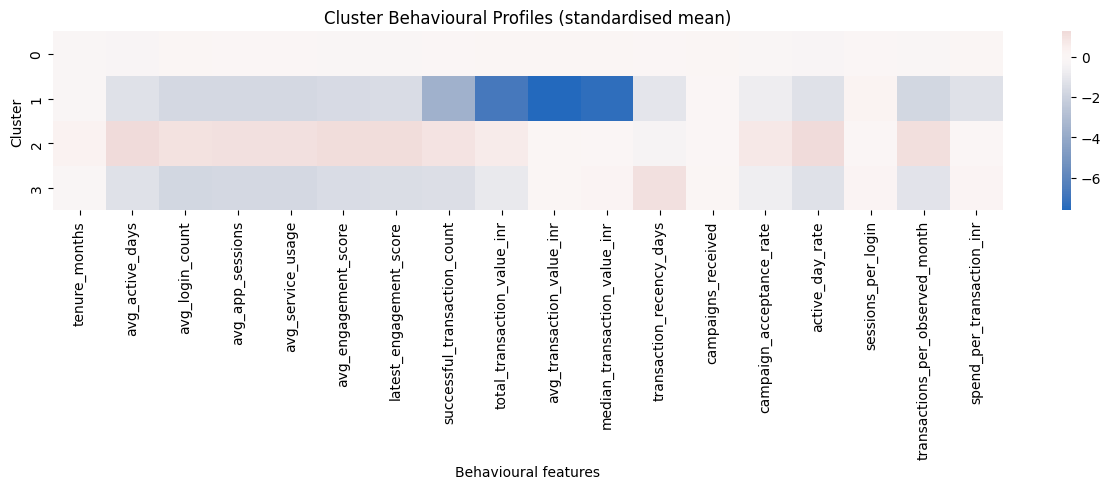

In [10]:
# Standardised mean profiles help compare relative highs/lows across features.
overall_mean = X.mean()
overall_std = X.std(ddof=0).replace(0, 1)
profile_z = (cluster_profile_mean - overall_mean) / overall_std

plt.figure(figsize=(max(10, X.shape[1] * 0.7), 5))
sns.heatmap(profile_z, cmap='vlag', center=0, annot=False)
plt.title('Cluster Behavioural Profiles (standardised mean)')
plt.xlabel('Behavioural features')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()


## 8. Create readable cluster descriptions

Do not assign labels such as Loyal or Dormant from cluster numbers alone. Inspect the cluster means/medians and describe each cluster based on observed behavioural patterns. Use this table to make that interpretation.

In [11]:
cluster_summary = cluster_profile_mean.copy()
cluster_summary.insert(
    0, 'customer_count',
    pd.Series(cluster_labels).value_counts().sort_index()
)
cluster_summary['customer_percentage'] = (
    cluster_summary['customer_count'] / len(segmentation) * 100
).round(2)

display(cluster_summary)


,customer_count,tenure_months,avg_active_days,avg_login_count,avg_app_sessions,avg_service_usage,avg_engagement_score,latest_engagement_score,successful_transaction_count,total_transaction_value_inr,avg_transaction_value_inr,median_transaction_value_inr,transaction_recency_days,campaigns_received,campaign_acceptance_rate,active_day_rate,sessions_per_login,transactions_per_observed_month,spend_per_transaction_inr,customer_percentage
cluster,,,,,,,,,,,,,,,,,,,,
0,10278,46.126386,10.173323,2.662610,2.260981,2.099087,50.559511,49.903250,2.286520,7.857750,5.691771,5.459530,54.853765,1.337875,0.232127,0.339111,0.647815,0.790677,346.224566,51.39
1,161,43.254658,1.992754,1.176457,0.904209,0.798939,11.471843,9.132298,0.000000,0.000000,0.000000,0.000000,0.000000,1.310546,0.048842,0.066425,0.686513,0.000000,0.000000,0.80
2,6146,62.755451,23.161880,3.520698,3.096085,2.921109,86.782113,86.796241,2.898272,8.482053,5.646021,5.387038,36.537585,1.329924,0.526035,0.772063,0.645411,1.471580,309.299704,30.73
3,3415,45.543192,1.784602,1.158280,0.885102,0.790484,13.469507,11.614319,1.398537,6.736541,5.669795,5.547453,115.692240,1.340257,0.058975,0.059487,0.680405,0.288043,387.396414,17.08


## 9. Export segmentation results and model artifacts

In [12]:
segmentation.to_csv(OUTPUT_DIR / 'customer_cluster_assignments.csv', index=False)
cluster_profile_mean.to_csv(OUTPUT_DIR / 'cluster_profile_mean.csv')
cluster_profile_median.to_csv(OUTPUT_DIR / 'cluster_profile_median.csv')
cluster_summary.to_csv(OUTPUT_DIR / 'cluster_summary.csv')

joblib.dump(final_model, OUTPUT_DIR / 'kmeans_model.joblib')
joblib.dump(scaler, OUTPUT_DIR / 'standard_scaler.joblib')

with open(OUTPUT_DIR / 'model_metadata.json', 'w') as f:
    json.dump({
        'algorithm': 'KMeans',
        'n_clusters': int(CHOSEN_K),
        'random_state': 42,
        'feature_columns': X.columns.tolist(),
        'removed_constant_columns': constant_cols
    }, f, indent=2)

print("Saved outputs to:", OUTPUT_DIR)
print("Files:", [p.name for p in OUTPUT_DIR.iterdir()])


Saved outputs to: /content/drive/MyDrive/customer_loyalty_synthetic_20k/customer_loyalty_synthetic_20k/processed/segmentation_outputs
Files: ['customer_cluster_assignments.csv', 'cluster_profile_mean.csv', 'cluster_profile_median.csv', 'cluster_summary.csv', 'kmeans_model.joblib', 'standard_scaler.joblib', 'model_metadata.json']


## 10. Handoff to Notebook 05

Before proceeding, record:
- The K you selected and why.
- The silhouette score for that K.
- The size of each cluster.
- The strongest behavioural features distinguishing each cluster.
- Any tiny or poorly separated clusters that may need investigation.

**Next:** Notebook 05 will focus on deeper clustering evaluation and interpretation. Billing/overdue status can be joined at that stage for a separate operational cross-tab, without changing the behavioural clustering inputs.
